# 🛡️ Unsupervised Anomaly Detection Masterclass
## Isolation Forest, DBSCAN & Local Outlier Factor (LOF) on Complex Geometry

### 📌 Notebook Objectives:
1. **Concentric Non-Linear Geometry**: Generate non-linear datasets using `make_circles` with both **global** and **local** injected anomalies.
2. **Isolation Forest Implementation**: Recursive random space-partitioning trees and 2D anomaly decision contour mapping.
3. **DBSCAN Clustering Implementation**: Density reachability on concentric circles with core, border, and noise classification.
4. **Theoretical Deep Dive**: What are **Global Outliers** vs. **Local Outliers**?
5. **The Fundamental Failure Modes**: Why Isolation Forest and DBSCAN **cannot reliably detect local outliers** in varying density distributions.
6. **Local Outlier Factor (LOF) Mathematical Foundation**: Step-by-step breakdown of $k$-distance, reachability distance, local reachability density ($\text{lrd}$), and LOF ratio.
7. **LOF Implementation & Score Computation**: Extracting true positive LOF scores from `negative_outlier_factor_` and visualizing anomaly magnitudes with radius-scaled bubble plots.
8. **Comprehensive Benchmark**: Multi-model comparison and high-yield interview questions & answers.


In [1]:
# ==============================================================================
# Environment Setup & Library Imports
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

# Suppress memory leak and thread warnings
os.environ["OMP_NUM_THREADS"] = "1"
warnings.filterwarnings('ignore')

from sklearn.datasets import make_circles, make_blobs
from sklearn.ensemble import IsolationForest
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler

# Visualization configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 110

print("All required machine learning libraries imported successfully!")

All required machine learning libraries imported successfully!


## 1. Non-Linear Geometry Generation: `make_circles` + Injected Anomalies

To evaluate anomaly detection algorithms on non-linear manifolds, we construct a synthetic dataset consisting of:
1. **Concentric Circles**: Generated via `make_circles(n_samples=600, factor=0.4, noise=0.05)` representing two distinct dense rings.
2. **Global Outliers**: Injected far outside both rings at extreme Euclidean coordinates.
3. **Local Outliers**: Injected in the intermediate "gap" between the inner and outer circles where density is noticeably lower than the adjacent rings.


Total Samples: 611
Normal Inliers: 600 | Global Outliers: 5 | Local Outliers: 6


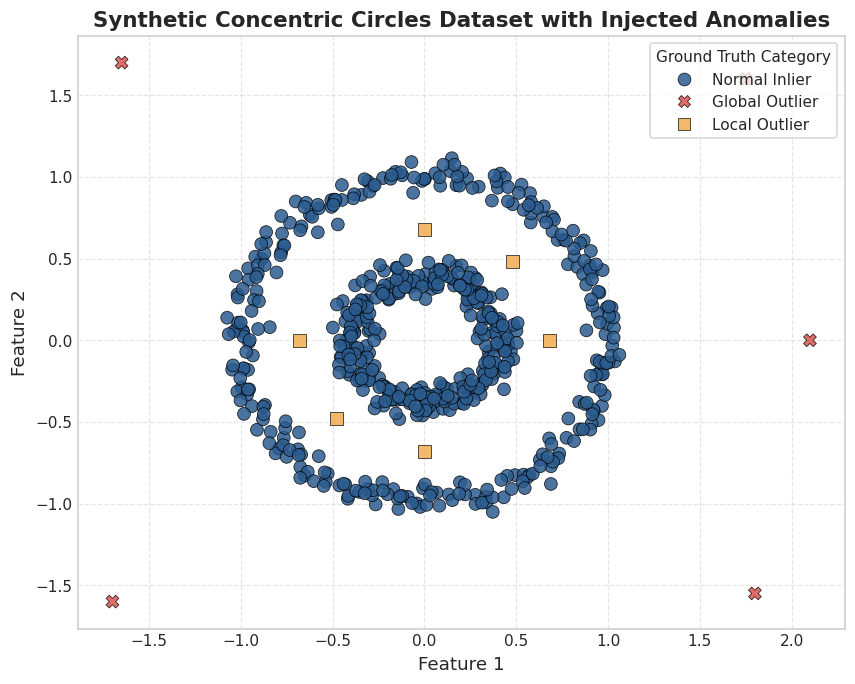

In [2]:
# Generate concentric circles
np.random.seed(42)
X_clean, _ = make_circles(n_samples=600, factor=0.4, noise=0.05, random_state=42)

# Injected Global Outliers (far outside the feature boundary)
global_outliers = np.array([
    [1.75,  1.60],
    [-1.65, 1.70],
    [1.80, -1.55],
    [-1.70, -1.60],
    [2.10,  0.00]
])

# Injected Local Outliers (located in the gap between the inner and outer circle)
# Note: Radius of inner circle ≈ 0.4, radius of outer circle ≈ 1.0.
# Local outliers are placed around radius r ≈ 0.65 - 0.70 (sparse intermediate gap)
local_outliers = np.array([
    [0.68,  0.00],
    [-0.68, 0.00],
    [0.00,  0.68],
    [0.00, -0.68],
    [0.48,  0.48],
    [-0.48, -0.48]
])

# Stack all samples into a unified dataset
X_circles = np.vstack([X_clean, global_outliers, local_outliers])

# Ground-truth labels: 1 = Normal Inlier, -2 = Global Outlier, -3 = Local Outlier
y_ground_truth = np.array([1]*len(X_clean) + [-2]*len(global_outliers) + [-3]*len(local_outliers))

df_circles = pd.DataFrame(X_circles, columns=['Feature_1', 'Feature_2'])
df_circles['Type'] = np.where(y_ground_truth == 1, 'Normal Inlier',
                     np.where(y_ground_truth == -2, 'Global Outlier', 'Local Outlier'))

print(f"Total Samples: {len(df_circles)}")
print(f"Normal Inliers: {len(X_clean)} | Global Outliers: {len(global_outliers)} | Local Outliers: {len(local_outliers)}")

# Visualize Ground Truth
plt.figure(figsize=(9, 7))
palette = {'Normal Inlier': '#2b5c8f', 'Global Outlier': '#d9534f', 'Local Outlier': '#f0ad4e'}
markers = {'Normal Inlier': 'o', 'Global Outlier': 'X', 'Local Outlier': 's'}

sns.scatterplot(
    data=df_circles, x='Feature_1', y='Feature_2',
    hue='Type', style='Type', palette=palette, markers=markers,
    s=70, alpha=0.85, edgecolor='black', linewidth=0.5
)
plt.title('Synthetic Concentric Circles Dataset with Injected Anomalies', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1', fontsize=12)
plt.ylabel('Feature 2', fontsize=12)
plt.legend(title='Ground Truth Category', loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 2. Isolation Forest Implementation on Concentric Geometry

### 🧠 Core Mathematical Intuition:
Isolation Forest (Liu, Ting, & Zhou, 2008) operates on a fundamentally different paradigm from profiling normal points:
Instead of modeling normal instances, it **isolates anomalies directly**.

1. **Tree Construction ($iTree$)**:
   - Randomly select a feature $q$.
   - Randomly select a split value $p$ uniformly between $\min(q)$ and $\max(q)$.
   - Recursively partition until either the tree reaches max height $\lceil \log_2(n) \rceil$, sample size $|X| \le 1$, or all points have identical values.
2. **Path Length $h(x)$**:
   - Number of edges $x$ traverses from the root node to the terminating leaf node.
   - **Anomalies are isolated near the root** (short path length $h(x)$) because they are sparse and distant.
   - **Normal points require many partitions** (long path length $h(x)$) to isolate.
3. **Anomaly Score Formulation**:
   $$s(x, n) = 2^{-\frac{E(h(x))}{c(n)}}$$
   where $c(n)$ is the average path length of unsuccessful searches in a Binary Search Tree (BST):
   $$c(n) = 2 \ln(n - 1) + 0.5772156649 - \frac{2(n - 1)}{n}$$
   - If $E(h(x)) \to 0 \implies s \to 1$: **Definite Anomaly**.
   - If $E(h(x)) \to c(n) \implies s \to 0.5$: **Indeterminate Instance**.
   - If $E(h(x)) \to n - 1 \implies s \to 0$: **Normal Instance**.


Isolation Forest identified 16 anomalies out of 611 samples.


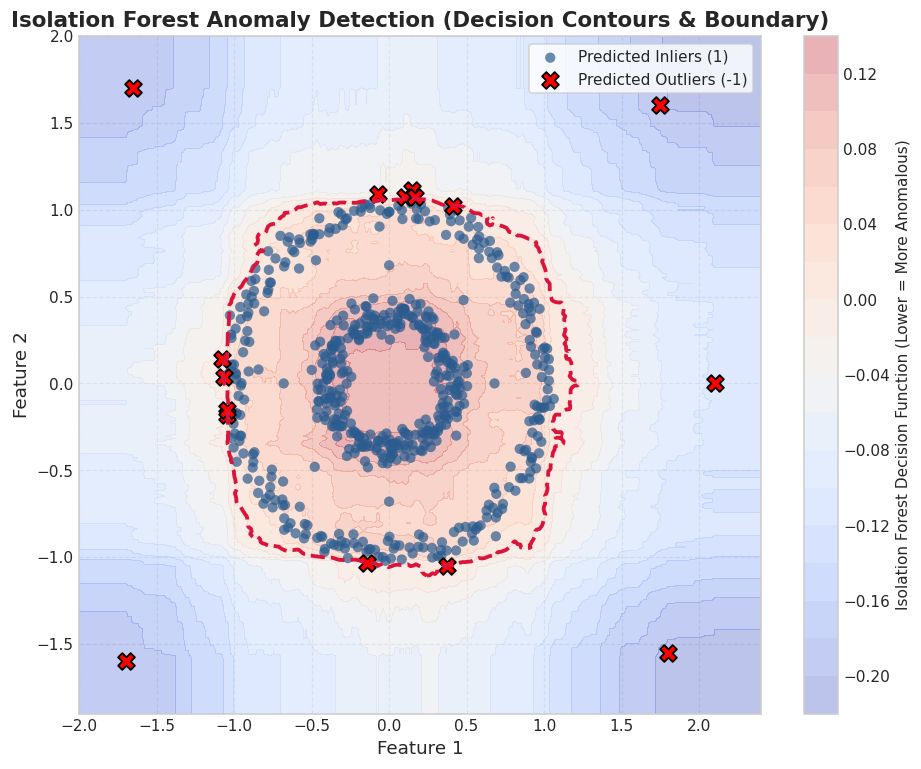

In [3]:
# ==============================================================================
# Fitting Isolation Forest on Concentric Geometry
# ==============================================================================
# Expected contamination fraction ≈ (5 global + 6 local) / 611 ≈ 0.018 -> set ~0.02 - 0.03
iso_forest = IsolationForest(
    n_estimators=150,
    contamination=0.025,
    random_state=42,
    n_jobs=-1
)

# Fit and predict: 1 for inlier, -1 for outlier
df_circles['IsoForest_Pred'] = iso_forest.fit_predict(X_circles)
# decision_function: lower (more negative) means more anomalous
df_circles['IsoForest_Score'] = iso_forest.decision_function(X_circles)

num_iso_outliers = np.sum(df_circles['IsoForest_Pred'] == -1)
print(f"Isolation Forest identified {num_iso_outliers} anomalies out of {len(X_circles)} samples.")

# ------------------------------------------------------------------------------
# 2D Anomaly Decision Contours Visualization
# ------------------------------------------------------------------------------
x_min, x_max = X_circles[:, 0].min() - 0.3, X_circles[:, 0].max() + 0.3
y_min, y_max = X_circles[:, 1].min() - 0.3, X_circles[:, 1].max() + 0.3
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
Z_iso = iso_forest.decision_function(np.c_[xx.ravel(), yy.ravel()])
Z_iso = Z_iso.reshape(xx.shape)

plt.figure(figsize=(10, 8))
# Decision contour fill
contour = plt.contourf(xx, yy, Z_iso, levels=20, cmap='coolwarm', alpha=0.35)
plt.colorbar(contour, label='Isolation Forest Decision Function (Lower = More Anomalous)')
# Decision boundary threshold level (level = 0 is default boundary)
plt.contour(xx, yy, Z_iso, levels=[0], linewidths=2.5, colors='crimson', linestyles='--')

# Scatter inliers and detected outliers
inliers_mask = (df_circles['IsoForest_Pred'] == 1)
outliers_mask = (df_circles['IsoForest_Pred'] == -1)

plt.scatter(X_circles[inliers_mask, 0], X_circles[inliers_mask, 1],
            c='#2b5c8f', s=45, alpha=0.7, edgecolors='none', label='Predicted Inliers (1)')
plt.scatter(X_circles[outliers_mask, 0], X_circles[outliers_mask, 1],
            c='red', marker='X', s=120, edgecolors='black', linewidth=1.2, label='Predicted Outliers (-1)')

plt.title('Isolation Forest Anomaly Detection (Decision Contours & Boundary)', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1', fontsize=12)
plt.ylabel('Feature 2', fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

## 3. DBSCAN Clustering Implementation on Concentric Geometry

### 🧠 Core Mathematical Intuition:
DBSCAN (Density-Based Spatial Clustering of Applications with Noise; Ester et al., 1996) discovers clusters of arbitrary shape by connecting dense contiguous regions:

1. **$\epsilon$-Neighborhood**: $N_\epsilon(p) = \{ q \in D \mid \text{dist}(p, q) \le \epsilon \}$.
2. **Core Point**: A point with at least $\text{MinPts}$ neighbors within radius $\epsilon$: $|N_\epsilon(p)| \ge \text{MinPts}$.
3. **Border Point**: Not a core point, but falls within the $\epsilon$-neighborhood of a core point.
4. **Noise Point**: Neither core nor border point; designated with label `cluster = -1`.

Because DBSCAN connects density-reachable points, it effortlessly traces concentric rings without assuming convex spherical shapes.


DBSCAN discovered 2 distinct clusters.
DBSCAN flagged 11 noise points (outliers with label -1).


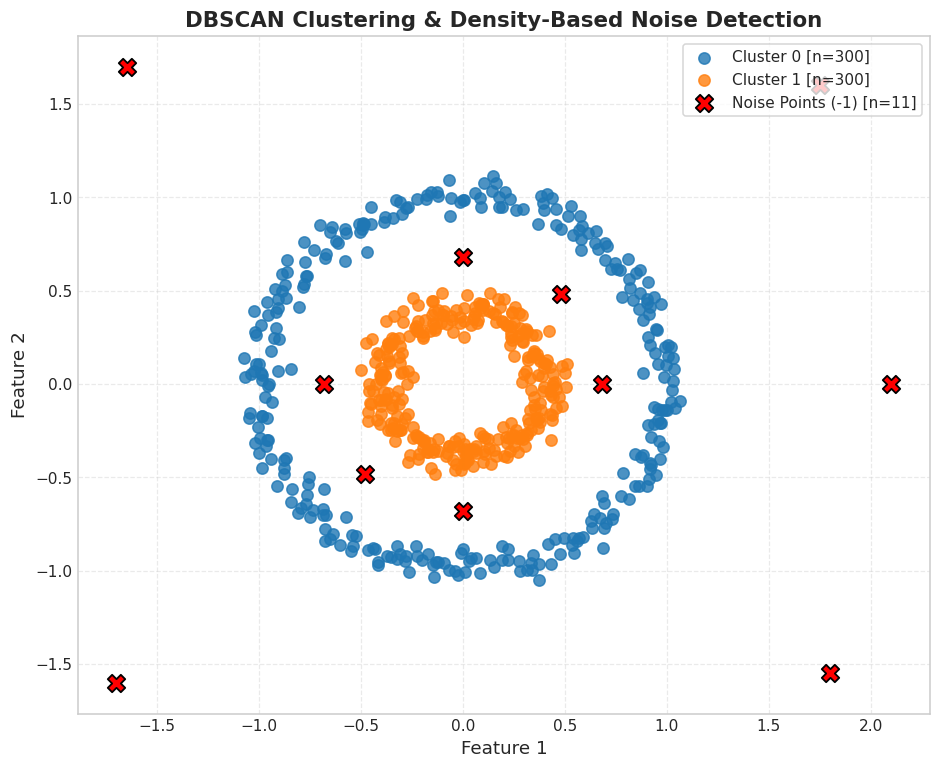

In [4]:
# ==============================================================================
# Fitting DBSCAN on Concentric Geometry
# ==============================================================================
dbscan = DBSCAN(eps=0.15, min_samples=6)
df_circles['DBSCAN_Cluster'] = dbscan.fit_predict(X_circles)

num_db_clusters = len(set(df_circles['DBSCAN_Cluster'])) - (1 if -1 in df_circles['DBSCAN_Cluster'].values else 0)
num_db_noise = np.sum(df_circles['DBSCAN_Cluster'] == -1)

print(f"DBSCAN discovered {num_db_clusters} distinct clusters.")
print(f"DBSCAN flagged {num_db_noise} noise points (outliers with label -1).")

# Visualize DBSCAN Clustering
plt.figure(figsize=(10, 8))

# Normal clusters in distinct colors, noise points in bold red X markers
unique_clusters = set(df_circles['DBSCAN_Cluster'])
cluster_colors = {c: plt.cm.tab10(i) for i, c in enumerate(unique_clusters if -1 not in unique_clusters else [c for c in unique_clusters if c != -1])}

for c in unique_clusters:
    if c == -1:
        mask = (df_circles['DBSCAN_Cluster'] == -1)
        plt.scatter(X_circles[mask, 0], X_circles[mask, 1],
                    c='red', marker='X', s=130, edgecolors='black', linewidth=1.2,
                    label=f'Noise Points (-1) [n={np.sum(mask)}]')
    else:
        mask = (df_circles['DBSCAN_Cluster'] == c)
        plt.scatter(X_circles[mask, 0], X_circles[mask, 1],
                    color=cluster_colors[c], s=55, alpha=0.8,
                    label=f'Cluster {c} [n={np.sum(mask)}]')

plt.title('DBSCAN Clustering & Density-Based Noise Detection', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1', fontsize=12)
plt.ylabel('Feature 2', fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

## 4. Conceptual Deep Dive: Global Outliers vs. Local Outliers

In modern unsupervised anomaly detection, anomalies fall into two distinct fundamental categories based on spatial and density context:

---

### 🌐 1. Global Outliers (Point Anomalies)
- **Definition**: An observation that deviates significantly from the **entire global distribution** of the dataset across the global coordinate space.
- **Geometric Characteristic**: It lies far away from **all** existing clusters, centroids, and high-density manifolds. Its absolute Euclidean distance to the nearest normal point is huge.
- **Real-World Examples**:
  - Credit card transaction of \$2,000,000 when all normal transactions across all users are below \$5,000.
  - Temperature sensor reading $900^\circ\text{C}$ in an office environment where normal readings are $18^\circ\text{C} - 28^\circ\text{C}$.
- **Detection**: Trivial for global methods (z-scores, box plots, Mahalanobis distance, Isolation Forest).

---

### 📍 2. Local Outliers (Density-Relative Anomalies)
- **Definition**: An observation that deviates significantly **relative to the local density of its immediate neighborhood**, even though its absolute feature values fall completely within the global range of normal data.
- **Geometric Characteristic**:
  - In a dataset with **varying density clusters** (e.g., Cluster $A$ is extremely dense with points spaced $0.05$ units apart, while Cluster $B$ is sparse with points spaced $0.8$ units apart).
  - A point $p$ placed at distance $0.35$ from Cluster $A$ has a local density that is drastically lower than its surrounding cluster members (making it an obvious outlier to Cluster $A$).
  - **However**, its absolute distance to Cluster $A$ ($0.35$) is actually **smaller** than the normal spacing between points inside Cluster $B$ ($0.8$)!
- **Real-World Examples**:
  - A patient with heart rate $65\text{ bpm}$ (normal globally), but their oxygen saturation is $75\%$ and age is $2$ months (relative to infants, this pattern is a severe local anomaly).
  - A retail transaction of \$300 at 2:00 AM in a small convenience store where all local 2:00 AM transactions are \$5 - \$15 (even though \$300 is a routine purchase at an electronics department).

---

### 📊 Comparison Summary Table

| Metric / Dimension | Global Outlier | Local Outlier |
|---|---|---|
| **Reference Frame** | Global feature domain $[\min(X), \max(X)]$ | Immediate $k$-nearest neighbors $N_k(p)$ |
| **Absolute Distance** | Very large to all normal clusters | Can be very small in absolute magnitude |
| **Density Sensitivity** | Independent of density variations | **Critically dependent on local relative density** |
| **Typical Cause** | Extreme measurement error, rare macro event | Contextual shift, subtle localized defect |
| **Isolation Forest Performance** | **Excellent** (isolated at shallow tree depths) | **Fails** (requires deep cuts like normal points) |
| **DBSCAN Performance** | **Excellent** (isolated as noise) | **Fails** (single global $\epsilon$ cannot adapt) |
| **Local Outlier Factor (LOF)** | **Excellent** | **State of the Art** (specifically designed for this) |


## 5. Why Isolation Forest & DBSCAN CANNOT Reliably Detect Local Outliers

Both **Isolation Forest** and **DBSCAN** are fundamentally designed around **global metrics**, making them structurally incapable of handling local outliers in multi-density environments.

---

### ❌ Failure Mode 1: Why Isolation Forest Fails on Local Outliers

1. **Global Axis-Aligned Partitions**:
   - Isolation Forest randomly selects a feature and draws a split uniformly between the minimum and maximum global bounds of that feature: $p \sim U(\min(x_j), \max(x_j))$.
   - Because local outliers reside **spatially close** to a dense cluster, a random cut across the wide global bounding box has an overwhelming probability of cutting somewhere far away, rather than neatly isolating the local outlier from its adjacent cluster.
2. **Path Length $h(x)$ Equality Trap**:
   - Isolating a point that is $0.3$ units away from a cluster of $300$ points requires nearly the same number of random cuts as isolating a normal point in a sparser cluster!
   - Consequently, the average path length $E(h(x))$ for a local outlier is **long**, virtually identical to normal inliers.
   - Its anomaly score $s(x, n) = 2^{-\frac{E(h(x))}{c(n)}}$ remains low ($< 0.5$), and it is misclassified as a normal inlier.

---

### ❌ Failure Mode 2: Why DBSCAN Fails on Local Outliers (The Global $\epsilon$ Dilemma)

DBSCAN requires a **single, global parameter pair**: radius $\epsilon$ and minimum neighbors $\text{MinPts}$. In any dataset where clusters have **varying local densities**, DBSCAN faces an insoluble dilemma:

$$\text{Density}(C_{\text{dense}}) \gg \text{Density}(C_{\text{sparse}})$$

1. **Scenario A (Tuning $\epsilon$ to the Sparse Cluster — $\epsilon = \epsilon_{\text{large}}$)**:
   - To prevent the sparse cluster from being discarded as noise, $\epsilon$ must be set large enough to bridge the points in the sparse cluster.
   - **The Consequence**: An $\epsilon$-neighborhood with $\epsilon_{\text{large}}$ centered on the local outlier easily captures points from the adjacent dense cluster. The local outlier satisfies the core/border point condition and is **absorbed into the cluster as an inlier**!
2. **Scenario B (Tuning $\epsilon$ to the Dense Cluster — $\epsilon = \epsilon_{\text{small}}$)**:
   - To isolate the local outlier from the dense cluster, $\epsilon$ must be made very small.
   - **The Consequence**: The entire valid sparse cluster completely fails to satisfy $|N_{\epsilon}(p)| \ge \text{MinPts}$ and is **erroneously discarded in its entirety as noise**!

> 💡 **Core Takeaway**: Because DBSCAN has a rigid global density cutoff, it cannot adapt to localized density gradients. This is precisely why **Local Outlier Factor (LOF)** was invented!


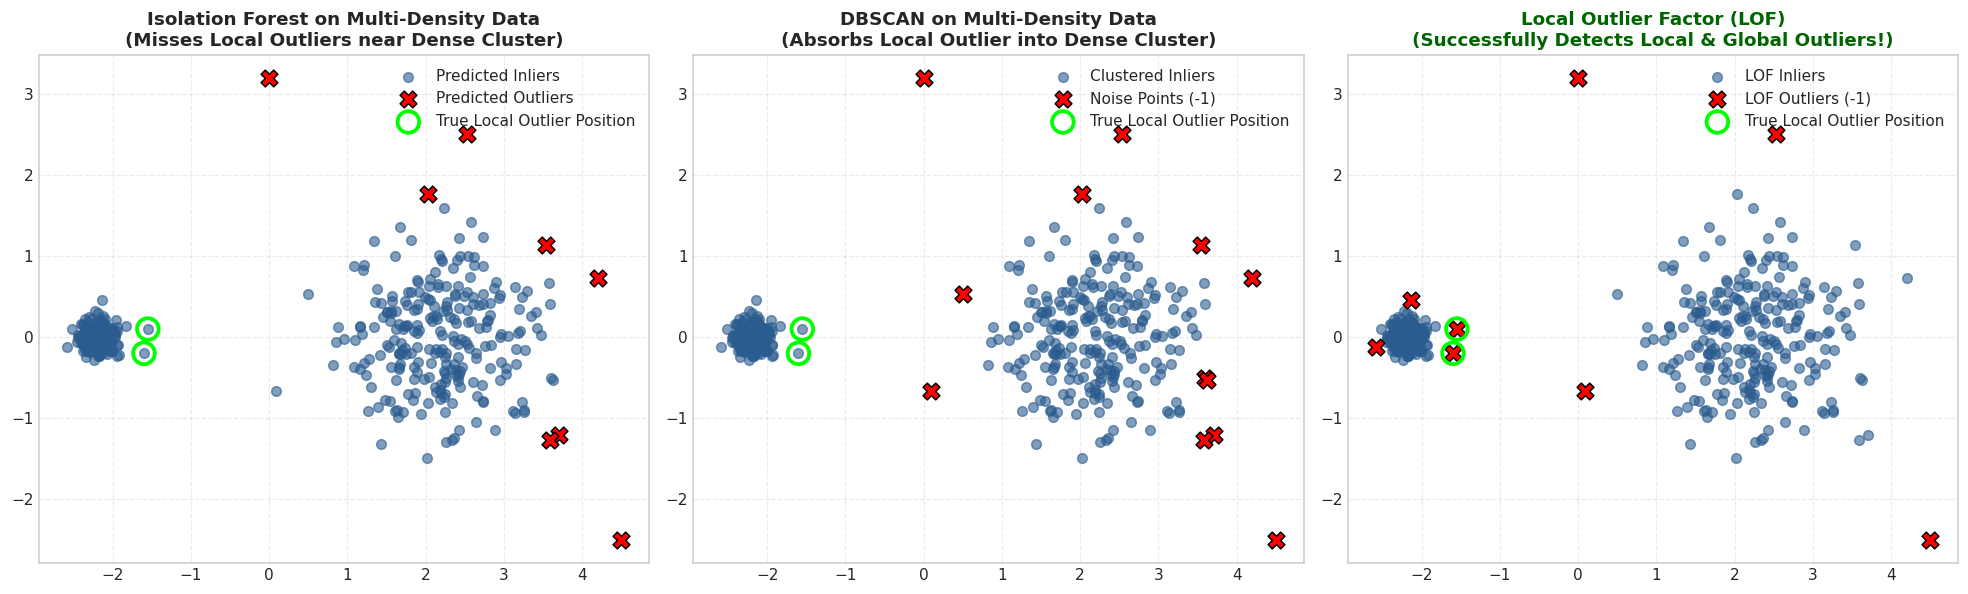

Local Outlier #1 LOF Score: 3.802 (Significant Anomaly!)
Local Outlier #2 LOF Score: 3.397 (Significant Anomaly!)
Typical Dense Cluster Inlier LOF Score: 1.226 (Normal)
Typical Sparse Cluster Inlier LOF Score: 1.226 (Normal)


In [5]:
# ==============================================================================
# Empirical Demonstration: Isolation Forest vs DBSCAN vs LOF on Multi-Density Data
# ==============================================================================
# Cluster 1: Extremely Dense Cluster (std = 0.12)
np.random.seed(42)
X_dense, _ = make_blobs(n_samples=250, centers=[[-2.2, 0.0]], cluster_std=0.12, random_state=42)

# Cluster 2: Sparse Cluster (std = 0.65)
X_sparse, _ = make_blobs(n_samples=250, centers=[[2.2, 0.0]], cluster_std=0.65, random_state=42)

# Local Outlier: Injected near the dense cluster (dist = 0.55 from center)
# Notice: Distance 0.55 is anomalous to dense cluster, but SMALLER than normal spacing in sparse cluster!
X_local_out = np.array([[-1.55, 0.10], [-1.60, -0.20]])

# Global Outlier: Injected far away from both clusters
X_global_out = np.array([[0.0, 3.2], [4.5, -2.5]])

X_multidensity = np.vstack([X_dense, X_sparse, X_local_out, X_global_out])

# 1. Fit Isolation Forest
iso_multi = IsolationForest(contamination=0.015, random_state=42)
iso_multi_preds = iso_multi.fit_predict(X_multidensity)

# 2. Fit DBSCAN (tuned with eps=0.45 to preserve the sparse cluster)
db_multi = DBSCAN(eps=0.45, min_samples=6)
db_multi_preds = db_multi.fit_predict(X_multidensity)

# 3. Fit Local Outlier Factor (LOF)
lof_multi = LocalOutlierFactor(n_neighbors=25, contamination=0.015)
lof_multi_preds = lof_multi.fit_predict(X_multidensity)
lof_multi_scores = -lof_multi.negative_outlier_factor_

# ------------------------------------------------------------------------------
# 3-Panel Visual Proof of Failure Modes
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Isolation Forest Plot
axes[0].scatter(X_multidensity[iso_multi_preds == 1, 0], X_multidensity[iso_multi_preds == 1, 1],
                c='#2b5c8f', s=40, alpha=0.6, label='Predicted Inliers')
axes[0].scatter(X_multidensity[iso_multi_preds == -1, 0], X_multidensity[iso_multi_preds == -1, 1],
                c='red', marker='X', s=120, edgecolors='black', label='Predicted Outliers')
axes[0].scatter(X_local_out[:, 0], X_local_out[:, 1], facecolors='none', edgecolors='lime',
                s=200, linewidth=2.5, label='True Local Outlier Position')
axes[0].set_title('Isolation Forest on Multi-Density Data\n(Misses Local Outliers near Dense Cluster)', fontweight='bold')
axes[0].legend(loc='upper right')
axes[0].grid(True, linestyle='--', alpha=0.4)

# DBSCAN Plot
axes[1].scatter(X_multidensity[db_multi_preds != -1, 0], X_multidensity[db_multi_preds != -1, 1],
                c='#2b5c8f', s=40, alpha=0.6, label='Clustered Inliers')
axes[1].scatter(X_multidensity[db_multi_preds == -1, 0], X_multidensity[db_multi_preds == -1, 1],
                c='red', marker='X', s=120, edgecolors='black', label='Noise Points (-1)')
axes[1].scatter(X_local_out[:, 0], X_local_out[:, 1], facecolors='none', edgecolors='lime',
                s=200, linewidth=2.5, label='True Local Outlier Position')
axes[1].set_title('DBSCAN on Multi-Density Data\n(Absorbs Local Outlier into Dense Cluster)', fontweight='bold')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.4)

# LOF Plot
axes[2].scatter(X_multidensity[lof_multi_preds == 1, 0], X_multidensity[lof_multi_preds == 1, 1],
                c='#2b5c8f', s=40, alpha=0.6, label='LOF Inliers')
axes[2].scatter(X_multidensity[lof_multi_preds == -1, 0], X_multidensity[lof_multi_preds == -1, 1],
                c='red', marker='X', s=120, edgecolors='black', label='LOF Outliers (-1)')
axes[2].scatter(X_local_out[:, 0], X_local_out[:, 1], facecolors='none', edgecolors='lime',
                s=200, linewidth=2.5, label='True Local Outlier Position')
axes[2].set_title('Local Outlier Factor (LOF)\n(Successfully Detects Local & Global Outliers!)', fontweight='bold', color='darkgreen')
axes[2].legend(loc='upper right')
axes[2].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

print(f"Local Outlier #1 LOF Score: {lof_multi_scores[-4]:.3f} (Significant Anomaly!)")
print(f"Local Outlier #2 LOF Score: {lof_multi_scores[-3]:.3f} (Significant Anomaly!)")
print(f"Typical Dense Cluster Inlier LOF Score: {lof_multi_scores[0]:.3f} (Normal)")
print(f"Typical Sparse Cluster Inlier LOF Score: {lof_multi_scores[250]:.3f} (Normal)")

## 6. Local Outlier Factor (LOF): Mathematical Foundation

Introduced by Markus M. Breunig, Hans-Peter Kriegel, Raymond T. Ng, and Jörg Sander (SIGMOD 2000), **LOF** is the foundational algorithm for density-relative anomaly detection.

Instead of applying a global threshold, LOF compares the local density of an object to the local densities of its $k$-nearest neighbors.

---

### 📐 Step 1: $k$-Distance of Point $p$ ($d_k(p)$)
For any positive integer $k$, the $k$-distance of point $p$, denoted $d_k(p)$, is the Euclidean distance $d(p, o)$ between $p$ and an object $o \in D$ such that:
1. For at least $k$ objects $o' \in D \setminus \{p\}$, it holds that $d(p, o') \le d(p, o)$.
2. For at most $k-1$ objects $o' \in D \setminus \{p\}$, it holds that $d(p, o') < d(p, o)$.

---

### 📐 Step 2: $k$-Distance Neighborhood of $p$ ($N_k(p)$)
The $k$-distance neighborhood of $p$ contains every point whose distance to $p$ is not greater than $d_k(p)$:
$$N_k(p) = \{ q \in D \setminus \{p\} \mid d(p, q) \le d_k(p) \}$$

---

### 📐 Step 3: Reachability Distance ($\text{reach-dist}_k(p, o)$)
The reachability distance of point $p$ with respect to object $o$ is:
$$\text{reach-dist}_k(p, o) = \max \left( d_k(o), \, d(p, o) \right)$$

> **Why this matters**: If point $p$ is far away from $o$, the reachability distance is simply their actual Euclidean distance $d(p, o)$. However, if $p$ and o are very close, the distance is bounded below by $d_k(o)$ (the $k$-distance of $o$). This prevents statistical instability and reduces noise fluctuations within dense clusters.

---

### 📐 Step 4: Local Reachability Density ($\text{lrd}_k(p)$)
The local reachability density of $p$ is the inverse of the average reachability distance based on the $k$-nearest neighbors of $p$:
$$\text{lrd}_k(p) = \frac{|N_k(p)|}{\sum_{o \in N_k(p)} \text{reach-dist}_k(p, o)}$$

- High $\text{lrd}_k(p) \implies$ Points are packed closely together (dense region).
- Low $\text{lrd}_k(p) \implies$ Points are widely separated (sparse region).

---

### 📐 Step 5: Local Outlier Factor ($\text{LOF}_k(p)$)
The Local Outlier Factor of $p$ is the **average ratio of the local reachability density of $p$'s neighbors to that of $p$**:
$$\text{LOF}_k(p) = \frac{\sum_{o \in N_k(p)} \frac{\text{lrd}_k(o)}{\text{lrd}_k(p)}}{|N_k(p)|} = \frac{\frac{1}{|N_k(p)|} \sum_{o \in N_k(p)} \text{lrd}_k(o)}{\text{lrd}_k(p)}$$

---

### 🎯 Step 6: Quantitative Interpretation of LOF Scores

| Calculated LOF Score | Relative Neighborhood Comparison | Physical Interpretation |
|---|---|---|
| **$\text{LOF}(p) \approx 1.0$** | $\text{lrd}(p) \approx \text{lrd}(\text{neighbors})$ | **Normal Inlier**: The point's local density matches that of its neighbors (true for both dense and sparse clusters). |
| **$\text{LOF}(p) < 1.0$** | $\text{lrd}(p) > \text{lrd}(\text{neighbors})$ | **Core Inlier**: The point is located deep inside a dense cluster core (even denser than its outer neighbors). |
| **$\text{LOF}(p) > 1.0$ ($1.5 - 2.5$)** | $\text{lrd}(p) < \text{lrd}(\text{neighbors})$ | **Mild Local Outlier**: The point is in a sparser area relative to its neighbors (border or transitional point). |
| **$\text{LOF}(p) \ge 3.0+$** | $\text{lrd}(p) \ll \text{lrd}(\text{neighbors})$ | **Extreme Anomaly**: Severe local or global outlier surrounded by significantly denser neighbors. |


In [6]:
# ==============================================================================
# Implementing Local Outlier Factor (LOF) on Concentric Circles Dataset
# ==============================================================================
# In scikit-learn:
# - `n_neighbors`: parameter k in the mathematical formulation (typically 15-35)
# - `contamination`: expected proportion of outliers (used to set the binary threshold)
# - `negative_outlier_factor_`: opposite of LOF score (-LOF)
#   Therefore: Positive LOF Score = -lof.negative_outlier_factor_

lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.025,
    novelty=False # False for standard transductive outlier detection
)

# Fit and predict binary label: 1 = Inlier, -1 = Outlier
df_circles['LOF_Pred'] = lof.fit_predict(X_circles)

# Extract and compute the true positive LOF score
df_circles['LOF_Score'] = -lof.negative_outlier_factor_

print("="*75)
print("LOCAL OUTLIER FACTOR (LOF) STATISTICAL SUMMARY")
print("="*75)
lof_stats = df_circles['LOF_Score'].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
display(pd.DataFrame(lof_stats).T)

# Show Top 11 Anomalous Points Ranked by LOF Score
top_anomalies = df_circles.sort_values(by='LOF_Score', ascending=False).head(11)
print("\nTop 11 Points Ranked by LOF Score:")
display(top_anomalies[['Feature_1', 'Feature_2', 'Type', 'LOF_Score', 'LOF_Pred']])

LOCAL OUTLIER FACTOR (LOF) STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
LOF_Score,611.0,1.057296,0.449564,0.960391,0.990481,1.000882,1.012471,1.035758,1.104676,2.068851,6.297729



Top 11 Points Ranked by LOF Score:


,Feature_1,Feature_2,Type,LOF_Score,LOF_Pred
600,1.75,1.60,Global Outlier,6.297729,-1
601,-1.65,1.70,Global Outlier,6.179262,-1
602,1.80,-1.55,Global Outlier,5.884630,-1
603,-1.70,-1.60,Global Outlier,5.812968,-1
604,2.10,0.00,Global Outlier,5.025496,-1
607,0.00,0.68,Local Outlier,2.219717,-1
609,0.48,0.48,Local Outlier,2.073690,-1
608,0.00,-0.68,Local Outlier,2.025300,-1
606,-0.68,0.00,Local Outlier,1.996264,-1
610,-0.48,-0.48,Local Outlier,1.913944,-1


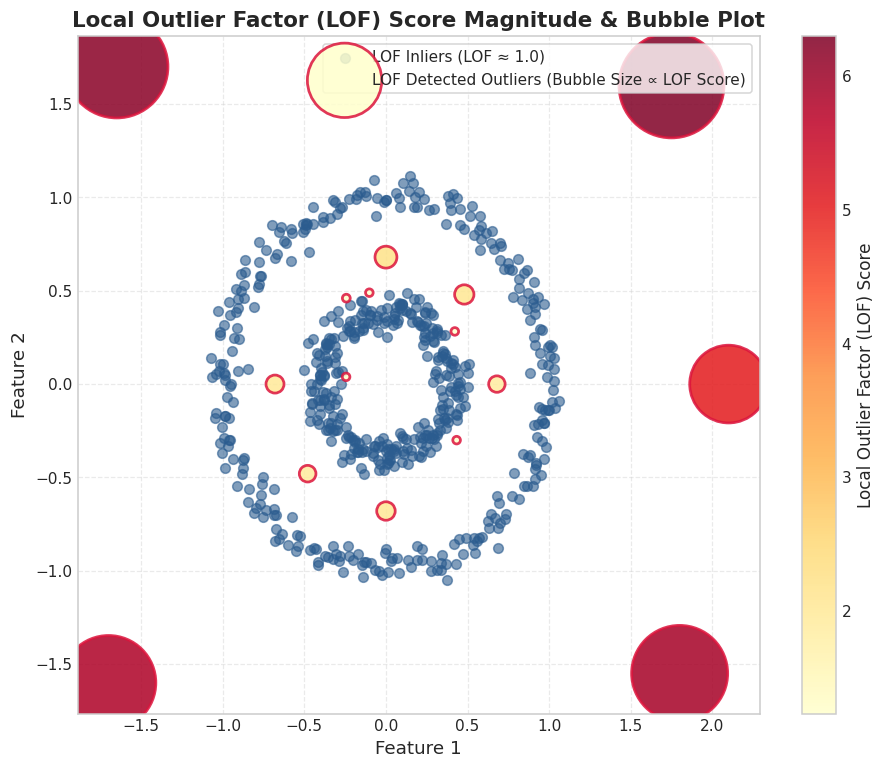

In [7]:
# ==============================================================================
# LOF Score Bubble Visualization (Radius Proportional to Anomaly Score)
# ==============================================================================
# To visualize anomaly intensity, scale the circle radius by (LOF_Score - 1):
# For normal points (LOF ≈ 1), the radius is very small.
# For outliers (LOF >> 1), the circle radius expands dramatically!

radius = (df_circles['LOF_Score'] - 1)
# Normalize radius for clean visual scaling
radius_scaled = np.maximum(radius, 0) ** 2.2 * 120 + 20

plt.figure(figsize=(10, 8))

# Scatter base points
inliers_lof = (df_circles['LOF_Pred'] == 1)
outliers_lof = (df_circles['LOF_Pred'] == -1)

plt.scatter(
    df_circles.loc[inliers_lof, 'Feature_1'],
    df_circles.loc[inliers_lof, 'Feature_2'],
    c='#2b5c8f', s=40, alpha=0.6, label='LOF Inliers (LOF ≈ 1.0)'
)

# Overlay anomaly bubbles sized by LOF score
scatter_bubbles = plt.scatter(
    df_circles.loc[outliers_lof, 'Feature_1'],
    df_circles.loc[outliers_lof, 'Feature_2'],
    s=radius_scaled[outliers_lof],
    c=df_circles.loc[outliers_lof, 'LOF_Score'],
    cmap='YlOrRd',
    edgecolors='crimson',
    linewidth=1.8,
    alpha=0.85,
    label='LOF Detected Outliers (Bubble Size ∝ LOF Score)'
)

cbar = plt.colorbar(scatter_bubbles)
cbar.set_label('Local Outlier Factor (LOF) Score', fontsize=11)

plt.title('Local Outlier Factor (LOF) Score Magnitude & Bubble Plot', fontsize=14, fontweight='bold')
plt.xlabel('Feature 1', fontsize=12)
plt.ylabel('Feature 2', fontsize=12)
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

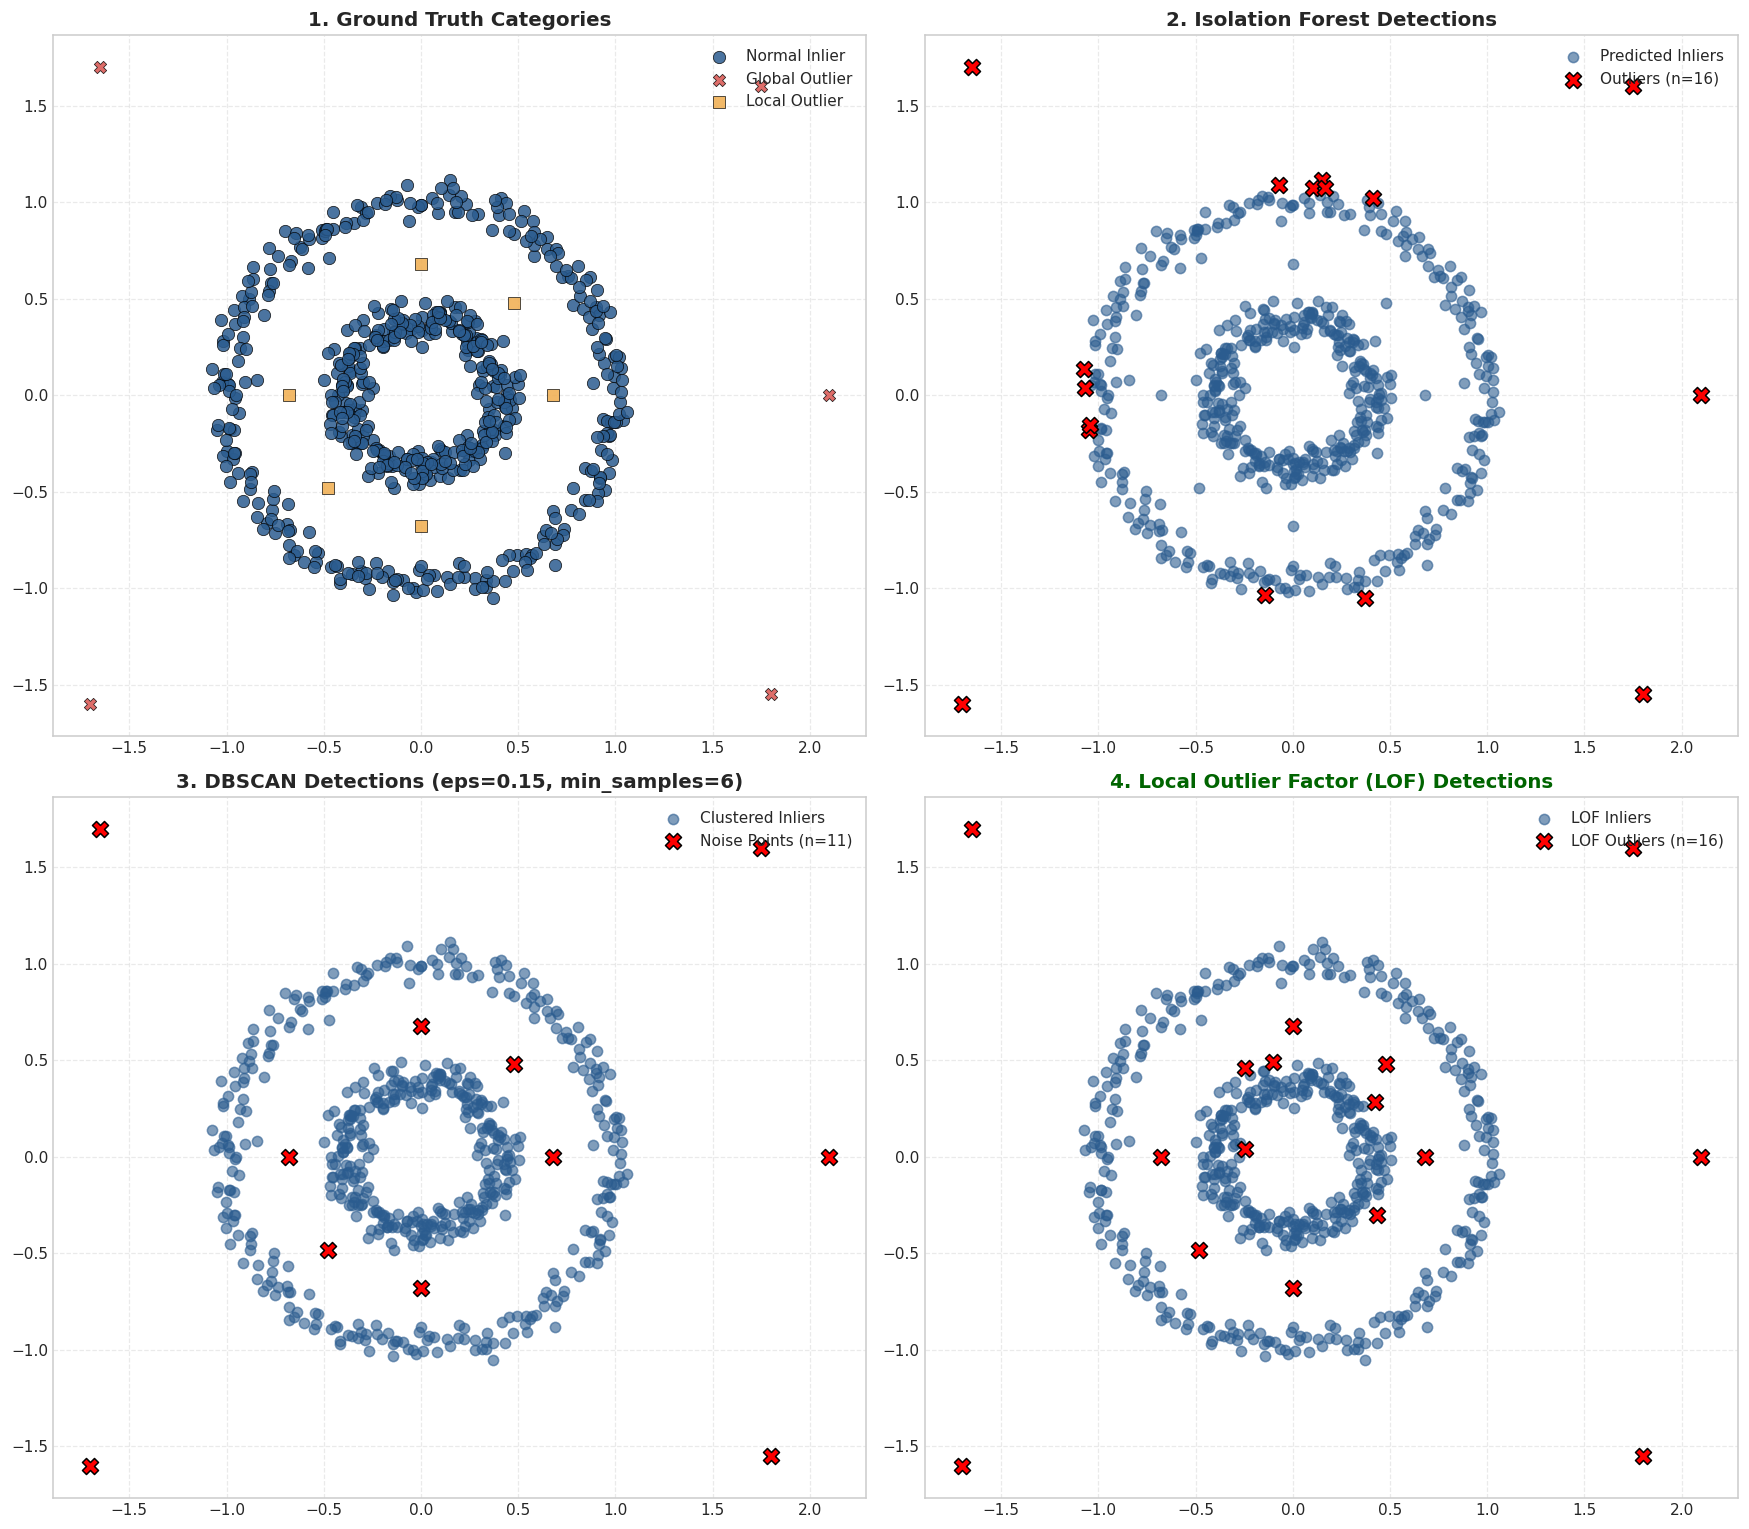

In [8]:
# ==============================================================================
# Grand Benchmark: Ground Truth vs Isolation Forest vs DBSCAN vs LOF
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 14))

# 1. Ground Truth
for cat, color, marker in [('Normal Inlier', '#2b5c8f', 'o'), ('Global Outlier', '#d9534f', 'X'), ('Local Outlier', '#f0ad4e', 's')]:
    sub = df_circles[df_circles['Type'] == cat]
    axes[0, 0].scatter(sub['Feature_1'], sub['Feature_2'], c=color, marker=marker,
                       s=65, alpha=0.85, edgecolors='black', linewidth=0.5, label=cat)
axes[0, 0].set_title('1. Ground Truth Categories', fontsize=13, fontweight='bold')
axes[0, 0].legend(loc='upper right')
axes[0, 0].grid(True, linestyle='--', alpha=0.4)

# 2. Isolation Forest
axes[0, 1].scatter(df_circles.loc[inliers_mask, 'Feature_1'], df_circles.loc[inliers_mask, 'Feature_2'],
                   c='#2b5c8f', s=45, alpha=0.6, label='Predicted Inliers')
axes[0, 1].scatter(df_circles.loc[outliers_mask, 'Feature_1'], df_circles.loc[outliers_mask, 'Feature_2'],
                   c='red', marker='X', s=110, edgecolors='black', label=f'Outliers (n={num_iso_outliers})')
axes[0, 1].set_title('2. Isolation Forest Detections', fontsize=13, fontweight='bold')
axes[0, 1].legend(loc='upper right')
axes[0, 1].grid(True, linestyle='--', alpha=0.4)

# 3. DBSCAN
db_inliers = (df_circles['DBSCAN_Cluster'] != -1)
db_noise = (df_circles['DBSCAN_Cluster'] == -1)
axes[1, 0].scatter(df_circles.loc[db_inliers, 'Feature_1'], df_circles.loc[db_inliers, 'Feature_2'],
                   c='#2b5c8f', s=45, alpha=0.6, label='Clustered Inliers')
axes[1, 0].scatter(df_circles.loc[db_noise, 'Feature_1'], df_circles.loc[db_noise, 'Feature_2'],
                   c='red', marker='X', s=110, edgecolors='black', label=f'Noise Points (n={num_db_noise})')
axes[1, 0].set_title('3. DBSCAN Detections (eps=0.15, min_samples=6)', fontsize=13, fontweight='bold')
axes[1, 0].legend(loc='upper right')
axes[1, 0].grid(True, linestyle='--', alpha=0.4)

# 4. Local Outlier Factor (LOF)
axes[1, 1].scatter(df_circles.loc[inliers_lof, 'Feature_1'], df_circles.loc[inliers_lof, 'Feature_2'],
                   c='#2b5c8f', s=45, alpha=0.6, label='LOF Inliers')
axes[1, 1].scatter(df_circles.loc[outliers_lof, 'Feature_1'], df_circles.loc[outliers_lof, 'Feature_2'],
                   c='red', marker='X', s=110, edgecolors='black', label=f'LOF Outliers (n={np.sum(outliers_lof)})')
axes[1, 1].set_title('4. Local Outlier Factor (LOF) Detections', fontsize=13, fontweight='bold', color='darkgreen')
axes[1, 1].legend(loc='upper right')
axes[1, 1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

## 7. Algorithm Comparison Matrix & Interview Cheat Sheet

### 📊 Comparative Analysis of Anomaly Detection Frameworks

| Feature / Criteria | Isolation Forest | DBSCAN | Local Outlier Factor (LOF) |
|---|---|---|---|
| **Core Detection Philosophy** | Random space isolation via binary trees | Density-reachable connected components | Relative neighborhood density ratio |
| **Output Type** | Continuous anomaly score $s \in [0, 1]$ + Binary flag | Discrete cluster labels + Noise flag ($-1$) | Continuous LOF score $\ge 0$ + Binary flag |
| **Handles Non-Linear Shapes?** | Moderate (axis-aligned orthogonal approximations) | **Yes** (arbitrary topological manifolds) | **Yes** (non-parametric neighborhood graph) |
| **Global Outlier Detection** | **Excellent** ($O(n \log n)$ time) | **Good** | **Excellent** |
| **Local Outlier Detection** | ❌ **Poor** (path lengths equalized) | ❌ **Poor** (global $\epsilon$ limitation) | **State-of-the-Art** |
| **Multi-Density Resilience** | ❌ **Fails** | ❌ **Fails** (discards sparse or merges local) | **Optimal** (density ratio normalization) |
| **Computational Complexity** | **$O(t \cdot n \log \psi)$** (Linear, highly scalable) | **$O(n \log n)$ to $O(n^2)$** | **$O(n^2)$** ($k$-NN search overhead) |
| **Novelty Detection (New Points)** | **Yes** (`predict()` on unseen data) | ❌ **No** (transductive only) | **Yes** (when `novelty=True`) |
| **Key Hyperparameters** | `n_estimators`, `contamination` | `eps` ($\epsilon$), `min_samples` | `n_neighbors` ($k$), `contamination` |

---

### 💼 Top 5 High-Yield Interview Questions & Answers

#### Q1: Why does Isolation Forest fail on local outliers in multi-density datasets?
> **Answer**: Isolation Forest generates random axis-aligned splits across the entire global domain $[\min(X_j), \max(X_j)]$. Because a local outlier is physically situated close to a dense cluster, a random cut has low probability of separating it immediately. It requires nearly the same depth of random cuts to isolate a local outlier as it does to isolate an ordinary point in a sparser cluster. Since its average path length $E(h(x))$ is not significantly shorter than normal points, its anomaly score remains low, causing it to escape detection.

#### Q2: What is the fundamental parameter dilemma in DBSCAN regarding local outliers?
> **Answer**: DBSCAN relies on a single global $\epsilon$ and $\text{MinPts}$. If clusters have varying densities:
> 1. Setting $\epsilon$ large enough to capture the sparse cluster causes the local outlier to fall well within $\epsilon$ of the adjacent dense cluster, classifying it as an inlier.
> 2. Setting $\epsilon$ small enough to isolate the local outlier causes the entire sparse cluster to fail the core point threshold, erroneously classifying the entire valid sparse cluster as noise.

#### Q3: What is the purpose of the reachability distance in the LOF formulation?
> **Answer**: Reachability distance $\text{reach-dist}_k(p, o) = \max(d_k(o), d(p, o))$ acts as a **statistical regularizer**. If point $p$ is extremely close to $o$ (e.g. inside a very tight cluster), their distance is bounded below by $d_k(o)$ (the $k$-distance of $o$). This prevents division by near-zero values and dampens minor statistical fluctuations in high-density regions.

#### Q4: How do you interpret an LOF score of 1.0, 0.8, and 3.5?
> **Answer**:
> - **$\text{LOF} = 1.0$**: Point has the exact same local density as its neighbors (normal inlier).
> - **$\text{LOF} = 0.8$**: Point has higher density than its neighbors (deep inside a dense cluster core).
> - **$\text{LOF} = 3.5$**: Point's local density is $3.5\times$ lower than that of its neighbors (significant anomaly / local outlier).

#### Q5: Can LOF be used for streaming or online inference?
> **Answer**: Standard LOF is transductive (evaluates existing data points). However, Scikit-Learn supports `LocalOutlierFactor(novelty=True)`, which fits a training distribution and enables `predict()` and `decision_function()` on new unseen test points by computing their reachability distance against the stored training neighborhood graph.
